Test PyTorch tensor operations and gradient calculation before implementing the Self-Attention model.

In [1]:
import torch

# Create two tensors
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
w = torch.tensor([0.5, 0.5, 0.5])

# Perform a simple computation
y = torch.sum(x * w)

# Calculate gradients using automatic differentiation
y.backward()

print("Input tensor:", x)
print("Computed output:", y.item())
print("Gradients:", x.grad)

Input tensor: tensor([1., 2., 3.], requires_grad=True)
Computed output: 3.0
Gradients: tensor([0.5000, 0.5000, 0.5000])


In [2]:
import torch
# Create two tensors
x = torch.tensor([2.0, 4.0, 6.0], requires_grad=True)
w = torch.tensor([1.0, 2.0, 3.0])

# perform a simple computation
y = torch.sum(x*w)

# calculate gradeint
y.backward()
print("input tensor:",x)
print("computed output:",y.item())
print("gradients:",x.grad)



input tensor: tensor([2., 4., 6.], requires_grad=True)
computed output: 28.0
gradients: tensor([1., 2., 3.])


Understand how PyTorch represents a batch of samples and how matrix multiplication works before implementing Query, Key, and Value projections.

In [3]:
import torch

# 2 samples, each containing 4 features
X = torch.tensor([
    [1.0, 2.0, 3.0, 4.0],
    [5.0, 6.0, 7.0, 8.0]
])

print("Input tensor:\n", X)
print("Shape:", X.shape)
print("Number of dimensions:", X.ndim)

# Project 4 input features into 3 dimensions
W = torch.randn(4, 3)
H = X @ W

print(W)
print("\nWeight matrix shape:", W.shape)
print("Projected tensor shape:", H.shape)

Input tensor:
 tensor([[1., 2., 3., 4.],
        [5., 6., 7., 8.]])
Shape: torch.Size([2, 4])
Number of dimensions: 2
tensor([[ 0.4274, -0.2131, -2.2032],
        [ 1.1866, -0.7009, -0.3762],
        [-0.3285,  1.3368,  2.1446],
        [-0.5448,  1.0099,  0.4926]])

Weight matrix shape: torch.Size([4, 3])
Projected tensor shape: torch.Size([2, 3])


In [4]:
import torch

X = torch.tensor([
    [1.0, 2.0, 3.0, 4.0],
    [5.0, 6.0, 7.0, 8.0]
])

W = torch.randn(4, 3)
H = X @ W

print("Input shape:", X.shape)
print("Weight shape:", W.shape)
print("Output shape:", H.shape)

Input shape: torch.Size([2, 4])
Weight shape: torch.Size([4, 3])
Output shape: torch.Size([2, 3])


Learn how an input tensor is projected into Query, Key, and Value representations using trainable linear transformations.

In [5]:
import torch
import torch.nn as nn

# 2 samples, 4 features per sample
X = torch.tensor([
    [1.0, 2.0, 3.0, 4.0],
    [5.0, 6.0, 7.0, 8.0]
])

# Project each sample into 3-dimensional Q, K, and V
query_layer = nn.Linear(4, 3)
key_layer = nn.Linear(4, 3)
value_layer = nn.Linear(4, 3)

Q = query_layer(X)
K = key_layer(X)
V = value_layer(X)

print(Q)
print(K)
print(V)

print("Input shape:", X.shape)
print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)


tensor([[ 2.7263, -2.1316, -1.4457],
        [ 6.8923, -4.3187, -5.6315]], grad_fn=<AddmmBackward0>)
tensor([[-0.2723, -2.0501, -2.3956],
        [-1.3948, -5.0971, -6.1860]], grad_fn=<AddmmBackward0>)
tensor([[ 0.1135,  3.3445, -0.2837],
        [-0.1659,  8.5255, -0.0212]], grad_fn=<AddmmBackward0>)
Input shape: torch.Size([2, 4])
Q shape: torch.Size([2, 3])
K shape: torch.Size([2, 3])
V shape: torch.Size([2, 3])


Calculate scaled dot-product attention scores using Query and Key matrices. The scores measure the similarity between representations.

In [6]:
import torch
import torch.nn as nn
import math

# Reproducible example
torch.manual_seed(42)

# 3 tokens, each represented by 4 features
X = torch.randn(3, 4)

# Create Query, Key and Value projections
query_layer = nn.Linear(4, 4)
key_layer = nn.Linear(4, 4)
value_layer = nn.Linear(4, 4)

Q = query_layer(X)
K = key_layer(X)
V = value_layer(X)

# Calculate scaled dot-product attention scores
d_k = K.shape[-1]
scores = (Q @ K.T) / math.sqrt(d_k)

print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("\nAttention scores:\n", scores)
print("\nScores shape:", scores.shape)

Q shape: torch.Size([3, 4])
K shape: torch.Size([3, 4])

Attention scores:
 tensor([[ 0.0306,  0.4329,  0.0606],
        [-0.3107, -0.9078, -0.5192],
        [ 0.0575,  0.5796,  0.1060]], grad_fn=<DivBackward0>)

Scores shape: torch.Size([3, 3])


Convert scaled attention scores into normalized attention weights using the Softmax function. Each row represents how strongly one token attends to all tokens.

In [ ]:
import torch
import torch.nn.functional as F
import math

torch.manual_seed(42)

# Three tokens, four features each
X = torch.randn(3, 4)

# Learnable Query and Key projections
query_layer = torch.nn.Linear(4, 4)
key_layer = torch.nn.Linear(4, 4)

Q = query_layer(X)
K = key_layer(X)

# Calculate scaled attention scores
d_k = K.shape[-1]
scores = (Q @ K.T) / math.sqrt(d_k)

# Step 2: Convert scores into attention weights
attention_weights = F.softmax(scores, dim=-1)

print("Raw scores:\n", scores)
print("\nAttention weights:\n", attention_weights)
print("\nRow sums:", attention_weights.sum(dim=-1))

Raw scores:
 tensor([[ 0.0306,  0.4329,  0.0606],
        [-0.3107, -0.9078, -0.5192],
        [ 0.0575,  0.5796,  0.1060]], grad_fn=<DivBackward0>)

Attention weights:
 tensor([[0.2836, 0.4241, 0.2923],
        [0.4233, 0.2330, 0.3437],
        [0.2677, 0.4513, 0.2810]], grad_fn=<SoftmaxBackward0>)

Row sums: tensor([1., 1., 1.], grad_fn=<SumBackward1>)


Multiply normalized attention weights by the Value matrix to obtain context-aware token representations.

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

torch.manual_seed(42)

# 3 tokens, 4 features per token
X = torch.randn(3, 4)

# Query, Key and Value projections
query_layer = nn.Linear(4, 4)
key_layer = nn.Linear(4, 4)
value_layer = nn.Linear(4, 4)

Q = query_layer(X)
K = key_layer(X)
V = value_layer(X)

# 1. Scaled dot-product scores
d_k = Q.shape[-1]
scores = (Q @ K.T) / math.sqrt(d_k)

# 2. Normalize scores
attention_weights = F.softmax(scores, dim=-1)

# 3. Combine Value vectors
attention_output = attention_weights @ V

print("Attention weights shape:", attention_weights.shape)
print("Value matrix shape:", V.shape)
print("\nAttention output:\n", attention_output)
print("\nAttention output shape:", attention_output.shape)

Attention weights shape: torch.Size([3, 3])
Value matrix shape: torch.Size([3, 4])

Attention output:
 tensor([[ 0.1719,  0.2484, -0.4549,  0.1084],
        [ 0.0006,  0.0132, -0.2425,  0.0426],
        [ 0.1964,  0.2812, -0.4836,  0.1166]], grad_fn=<MmBackward0>)

Attention output shape: torch.Size([3, 4])


Implement scaled dot-product Self-Attention as a reusable PyTorch module. The input will contain a batch of samples, each with multiple tokens and an embedding vector for every token.

In [9]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


class SelfAttention(nn.Module):
    def __init__(self, embed_dim):
        super().__init__()

        self.query = nn.Linear(embed_dim, embed_dim)
        self.key = nn.Linear(embed_dim, embed_dim)
        self.value = nn.Linear(embed_dim, embed_dim)

        self.scale = math.sqrt(embed_dim)

    def forward(self, x):
        # x shape: (batch_size, num_tokens, embed_dim)

        Q = self.query(x)
        K = self.key(x)
        V = self.value(x)

        # (B, N, D) @ (B, D, N) -> (B, N, N)
        scores = torch.matmul(Q, K.transpose(-2, -1))
        scores = scores / self.scale

        # Normalize attention scores across tokens
        weights = F.softmax(scores, dim=-1)

        # (B, N, N) @ (B, N, D) -> (B, N, D)
        output = torch.matmul(weights, V)

        return output, weights


# Test the module with synthetic tensors
torch.manual_seed(42)

batch_size = 2
num_tokens = 5
embed_dim = 8

x = torch.randn(batch_size, num_tokens, embed_dim)

attention = SelfAttention(embed_dim)
output, weights = attention(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)
print("Attention weights shape:", weights.shape)
print("Attention row sums:\n", weights.sum(dim=-1))

assert output.shape == x.shape
assert weights.shape == (batch_size, num_tokens, num_tokens)
assert torch.allclose(
    weights.sum(dim=-1),
    torch.ones(batch_size, num_tokens),
    atol=1e-6
)

print("\nSelf-Attention test passed!")

Input shape: torch.Size([2, 5, 8])
Output shape: torch.Size([2, 5, 8])
Attention weights shape: torch.Size([2, 5, 5])
Attention row sums:
 tensor([[1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
        [1.0000, 1.0000, 1.0000, 1.0000, 1.0000]], grad_fn=<SumBackward1>)

Self-Attention test passed!


Combine the custom Self-Attention layer with a pooling operation and a compact classification head. The model will convert token representations into class logits.

In [10]:
import torch
import torch.nn as nn


class SelfAttentionClassifier(nn.Module):
    def __init__(
        self,
        embed_dim=8,
        hidden_dim=16,
        num_classes=3,
        dropout=0.3
    ):
        super().__init__()

        self.attention = SelfAttention(embed_dim)

        self.classifier = nn.Sequential(
            nn.Linear(embed_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x):
        # x shape: (batch_size, num_tokens, embed_dim)
        attention_output, attention_weights = self.attention(x)

        # Average across tokens
        pooled = attention_output.mean(dim=1)

        # Return raw class logits
        logits = self.classifier(pooled)

        return logits, attention_weights


# Synthetic architecture test
torch.manual_seed(42)

model = SelfAttentionClassifier(
    embed_dim=8,
    hidden_dim=16,
    num_classes=3,
    dropout=0.3
)

x = torch.randn(4, 5, 8)

logits, weights = model(x)

print("Input shape:", x.shape)
print("Logits shape:", logits.shape)
print("Attention weights shape:", weights.shape)

trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
print("Trainable parameters:", trainable_params)

assert logits.shape == (4, 3)
assert weights.shape == (4, 5, 5)

print("Classifier architecture test passed!")

Input shape: torch.Size([4, 5, 8])
Logits shape: torch.Size([4, 3])
Attention weights shape: torch.Size([4, 5, 5])
Trainable parameters: 411
Classifier architecture test passed!


Loss, Backpropagation & Optimizer
Notebook mein ek new code cell banao aur ye code run karo.

In [ ]:

# Test one training step with synthetic data

import torch
import torch.nn as nn

# 1. Create a small synthetic batch
torch.manual_seed(42)

x = torch.randn(4, 5, 8)

# Three possible classes: 0, 1, 2
y = torch.tensor([0, 1, 2, 1], dtype=torch.long)

# 2. Define loss function and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# 3. Training mode
model.train()

# 4. Clear previous gradients
optimizer.zero_grad()

# 5. Forward pass
logits, attention_weights = model(x)

# 6. Calculate loss
loss = criterion(logits, y)

# 7. Backpropagation
loss.backward()

# 8. Check whether gradients were calculated
gradient_exists = any(
    p.grad is not None
    for p in model.parameters()
    if p.requires_grad
)

# 9. Update model parameters
optimizer.step()

print(f"Training loss: {loss.item():.4f}")
print("Gradient calculated:", gradient_exists)
print("Optimizer update completed.")
print("Training-step test passed!")


Training loss: 1.0478
Gradient calculated: True
Optimizer update completed.
Training-step test passed!


In [1]:

from pathlib import Path

# Project folder ke andar data/raw directory
DATA_DIR = Path("data/raw")

print("Current working directory:", Path.cwd())
print("Data directory exists:", DATA_DIR.exists())

if DATA_DIR.exists():
    for file in sorted(DATA_DIR.iterdir()):
        if file.is_file():
            print(f"{file.name}  |  {file.stat().st_size / (1024**2):.2f} MB")
else:
    print("\nFolder nahi mila. Apne project folder ka path check karo.")


Current working directory: d:\AI Reserch & Project Journey\projects\self attention classifier\notebooks
Data directory exists: False

Folder nahi mila. Apne project folder ka path check karo.


In [13]:

from pathlib import Path

# Notebook folder se project root par jaana
PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "raw"

print("Project folder:", PROJECT_DIR)
print("Project folder exists:", PROJECT_DIR.exists())
print("Data folder exists:", DATA_DIR.exists())

if DATA_DIR.exists():
    print("\nFiles found:")
    for file in sorted(DATA_DIR.iterdir()):
        if file.is_file():
            print(f"{file.name} | {file.stat().st_size / (1024**2):.2f} MB")
else:
    print("\nData folder nahi mila.")
    print("Project root ke folders:", [
        p.name for p in PROJECT_DIR.iterdir() if p.is_dir()
    ])


Project folder: d:\AI Reserch & Project Journey\projects\rna-transformer
Project folder exists: True
Data folder exists: True

Files found:
.gitkeep | 0.00 MB
41597_2025_4597_MOESM1_ESM.xlsx | 0.02 MB
GSE272042_tpmALL.csv.gz | 3.26 MB


In [14]:

import pandas as pd

# Load both files for inspection
csv_path = DATA_DIR / "GSE272042_tpmALL.csv.gz"
excel_path = DATA_DIR / "41597_2025_4597_MOESM1_ESM.xlsx"

expression_df = pd.read_csv(csv_path, compression="gzip")
metadata_df = pd.read_excel(excel_path)

print("=== GENE EXPRESSION DATA ===")
print("Shape:", expression_df.shape)
print("Columns:", expression_df.columns.tolist()[:10])
display(expression_df.head())

print("\n=== EXCEL / METADATA FILE ===")
print("Shape:", metadata_df.shape)
print("Columns:", metadata_df.columns.tolist())
display(metadata_df.head())


=== GENE EXPRESSION DATA ===
Shape: (40232, 154)
Columns: ['Unnamed: 0', '126', '134', '140', '156', '157', '159', '160', '161', '171']


,Unnamed: 0,126,134,140,156,157,159,160,161,171,...,24,35,54,68,76,77,79,8,89,90
0,MT-TF,8,11,9,13,8,6,3,12,0,...,19,10,3,0,0,6,3,5,0,0
1,MT-RNR1,1557,2399,1984,1007,2835,4330,2825,5246,4078,...,4876,1958,2892,2011,1503,4174,2535,2574,1840,1235
2,MT-TV,0,3,0,4,8,3,6,8,0,...,5,0,0,0,0,6,0,7,0,0
3,MT-RNR2,9468,9402,7450,2929,4305,9189,7045,8145,11246,...,13803,4966,11457,5210,4113,7952,14149,10371,5356,3794
4,MT-TL1,38,25,18,4,8,3,10,12,3,...,24,3,14,3,2,8,7,20,3,0



=== EXCEL / METADATA FILE ===
Shape: (187, 4)
Columns: ['Supplementary Table S1. Overview of the samples with the GEO identifiers.', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3']


,Supplementary Table S1. Overview of the samples with the GEO identifiers.,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,NaN,NaN,NaN
1,Sample,RNA-seq,Methylation beadchips,Diagnosis
2,Sample 100,GSM8391697,GSM8461219,"Glioblastoma, IDH wildtype"
3,Sample 102,GSM8391676,GSM8461203,Supratentorial ependymoma
4,Sample 104,GSM8391763,NaN,"Glioblastoma, IDH wildtype"


In [15]:

# Read Excel without assuming its first row contains the headers
metadata_raw = pd.read_excel(excel_path, header=None)

print("First 6 rows of the Excel file:")
display(metadata_raw.head(6))

# Extract the row containing the actual column names
print("\nPotential column-header row:")
display(metadata_raw.iloc[1])


First 6 rows of the Excel file:


,0,1,2,3
0,Supplementary Table S1. Overview of the sample...,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN
2,Sample,RNA-seq,Methylation beadchips,Diagnosis
3,Sample 100,GSM8391697,GSM8461219,"Glioblastoma, IDH wildtype"
4,Sample 102,GSM8391676,GSM8461203,Supratentorial ependymoma
5,Sample 104,GSM8391763,NaN,"Glioblastoma, IDH wildtype"



Potential column-header row:


0    NaN
1    NaN
2    NaN
3    NaN
Name: 1, dtype: str

In [16]:

# Correct header is at row index 2
metadata_df = pd.read_excel(excel_path, header=2)

# Remove completely empty rows
metadata_df = metadata_df.dropna(how="all")

# Clean column names
metadata_df.columns = metadata_df.columns.astype(str).str.strip()

print("Metadata shape:", metadata_df.shape)
print("\nColumn names:")
print(metadata_df.columns.tolist())

print("\nFirst 10 sample records:")
display(metadata_df.head(10))

print("\nDiagnosis counts:")
if "Diagnosis" in metadata_df.columns:
    print(metadata_df["Diagnosis"].value_counts(dropna=False))


Metadata shape: (185, 4)

Column names:
['Sample', 'RNA-seq', 'Methylation beadchips', 'Diagnosis']

First 10 sample records:


,Sample,RNA-seq,Methylation beadchips,Diagnosis
0,Sample 100,GSM8391697,GSM8461219,"Glioblastoma, IDH wildtype"
1,Sample 102,GSM8391676,GSM8461203,Supratentorial ependymoma
2,Sample 104,GSM8391763,NaN,"Glioblastoma, IDH wildtype"
3,Sample 105,GSM8391666,GSM8461186,"Glioblastoma, IDH wildtype"
4,Sample 106,GSM8391698,NaN,"Glioblastoma, IDH wildtype"
5,Sample 109,GSM8391699,GSM8461193,"Glioblastoma, IDH wildtype"
6,Sample 110,GSM8391667,GSM8461211,"Glioblastoma, IDH wildtype"
7,Sample 117,GSM8391747,NaN,"Glioblastoma, IDH wildtype"
8,Sample 12,GSM8391658,GSM8461226,Supratentorial ependymoma
9,Sample 120,GSM8391783,GSM8461265,"Glioblastoma, IDH wildtype"



Diagnosis counts:
Diagnosis
Glioblastoma, IDH wildtype                                       139
Oligodendroglioma, IDH-mutant  and  1p/19q-codeleted, grade 2     10
Supratentorial ependymoma                                          9
Astrocytoma, IDH-mutant, grade 2                                   8
Pilocytic astrocytoma                                              7
Astrocytoma, IDH-mutant, grade 3                                   5
Oligodendroglioma, IDH-mutant  and  1p/19q-codeleted, grade 3      4
Ganglioglioma                                                      3
Name: count, dtype: int64


In [17]:

# Compare RNA-seq sample IDs with expression-data columns

# CSV ke sample columns (first column genes ke names hain)
expression_sample_ids = set(expression_df.columns[1:].astype(str))

# Excel ke RNA-seq IDs
metadata_sample_ids = set(
    metadata_df["RNA-seq"].dropna().astype(str).str.strip()
)

matched_ids = expression_sample_ids & metadata_sample_ids
expression_only = expression_sample_ids - metadata_sample_ids
metadata_only = metadata_sample_ids - expression_sample_ids

print("Expression sample columns:", len(expression_sample_ids))
print("Metadata RNA-seq IDs:", len(metadata_sample_ids))
print("Matched sample IDs:", len(matched_ids))
print("Expression-only IDs:", len(expression_only))
print("Metadata-only IDs:", len(metadata_only))

print("\nExample expression IDs:")
print(sorted(expression_sample_ids)[:10])

print("\nExample metadata RNA-seq IDs:")
print(sorted(metadata_sample_ids)[:10])

print("\nExample matched IDs:")
print(sorted(matched_ids)[:10])


Expression sample columns: 153
Metadata RNA-seq IDs: 153
Matched sample IDs: 0
Expression-only IDs: 153
Metadata-only IDs: 153

Example expression IDs:
['100', '102', '104', '105', '106', '109', '110', '117', '12', '120']

Example metadata RNA-seq IDs:
['GSM8391641', 'GSM8391642', 'GSM8391643', 'GSM8391644', 'GSM8391645', 'GSM8391646', 'GSM8391647', 'GSM8391648', 'GSM8391649', 'GSM8391650']

Example matched IDs:
[]


In [18]:

# Compare CSV column IDs with the Excel "Sample" column

expression_ids = set(
    expression_df.columns[1:].astype(str).str.strip()
)

metadata_sample_names = set(
    metadata_df["Sample"].dropna().astype(str).str.strip()
)

print("CSV sample IDs:", len(expression_ids))
print("Excel Sample names:", len(metadata_sample_names))
print("Matched sample names:", len(expression_ids & metadata_sample_names))

print("\nCSV IDs not found in Excel Sample column:")
print(sorted(expression_ids - metadata_sample_names)[:15])

print("\nExcel Sample names not found in CSV:")
print(sorted(metadata_sample_names - expression_ids)[:15])


CSV sample IDs: 153
Excel Sample names: 185
Matched sample names: 0

CSV IDs not found in Excel Sample column:
['100', '102', '104', '105', '106', '109', '110', '117', '12', '120', '121', '122', '126', '128', '132']

Excel Sample names not found in CSV:
['Sample 100', 'Sample 102', 'Sample 104', 'Sample 105', 'Sample 106', 'Sample 109', 'Sample 110', 'Sample 117', 'Sample 12', 'Sample 120', 'Sample 121', 'Sample 122', 'Sample 126', 'Sample 128', 'Sample 132']


In [19]:

# Normalize sample names to their numeric IDs
# Example: "Sample 100" -> "100"

import re

def normalize_sample_id(value):
    match = re.fullmatch(r"\s*(?:Sample\s*)?(\d+)\s*", str(value), re.IGNORECASE)
    return match.group(1) if match else None

expression_ids = {
    normalize_sample_id(col)
    for col in expression_df.columns[1:]
}
expression_ids.discard(None)

metadata_df["Sample_ID"] = metadata_df["Sample"].apply(normalize_sample_id)

metadata_ids = set(metadata_df["Sample_ID"].dropna())
matched_ids = expression_ids & metadata_ids

print("CSV sample IDs:", len(expression_ids))
print("Excel sample IDs:", len(metadata_ids))
print("Matched IDs:", len(matched_ids))

print("\nExample matched IDs:")
print(sorted(matched_ids, key=int)[:15])

print("\nExample unmatched CSV IDs:")
print(sorted(expression_ids - metadata_ids, key=int)[:15])


CSV sample IDs: 153
Excel sample IDs: 185
Matched IDs: 153

Example matched IDs:
['2', '3', '8', '12', '16', '19', '24', '29', '31', '32', '35', '36', '41', '42', '46']

Example unmatched CSV IDs:
[]


In [20]:

# Check whether sample IDs are unique in the metadata

print("Total metadata rows:", len(metadata_df))
print("Non-missing sample IDs:", metadata_df["Sample_ID"].notna().sum())
print("Unique sample IDs:", metadata_df["Sample_ID"].nunique())

# Find duplicate sample IDs
duplicate_mask = metadata_df["Sample_ID"].duplicated(keep=False)
duplicates = metadata_df.loc[
    duplicate_mask,
    ["Sample", "Sample_ID", "RNA-seq", "Diagnosis"]
].sort_values("Sample_ID")

print("\nNumber of rows with duplicate sample IDs:", len(duplicates))

if duplicates.empty:
    print("No duplicate sample IDs found.")
else:
    display(duplicates)


Total metadata rows: 185
Non-missing sample IDs: 185
Unique sample IDs: 185

Number of rows with duplicate sample IDs: 0
No duplicate sample IDs found.


In [21]:

# Build a sample-to-diagnosis mapping from the metadata
sample_labels = metadata_df.set_index("Sample_ID")["Diagnosis"]

# Keep only expression samples that have matching metadata
sample_order = [
    normalize_sample_id(col)
    for col in expression_df.columns[1:]
]

labels = pd.Series(sample_order, name="Sample_ID").map(sample_labels)

print("Expression samples:", len(sample_order))
print("Mapped labels:", labels.notna().sum())
print("Missing labels:", labels.isna().sum())

print("\nDiagnosis distribution among expression samples:")
print(labels.value_counts(dropna=False))

# Show any samples with missing diagnosis labels
if labels.isna().any():
    missing_samples = [
        expression_df.columns[i + 1]
        for i, label in enumerate(labels)
        if pd.isna(label)
    ]
    print("\nSamples with missing labels:", missing_samples)


Expression samples: 153
Mapped labels: 153
Missing labels: 0

Diagnosis distribution among expression samples:
Sample_ID
Glioblastoma, IDH wildtype                                       113
Oligodendroglioma, IDH-mutant  and  1p/19q-codeleted, grade 2      9
Astrocytoma, IDH-mutant, grade 2                                   7
Supratentorial ependymoma                                          7
Pilocytic astrocytoma                                              6
Astrocytoma, IDH-mutant, grade 3                                   5
Ganglioglioma                                                      3
Oligodendroglioma, IDH-mutant  and  1p/19q-codeleted, grade 3      3
Name: count, dtype: int64


In [22]:

import numpy as np

# Extract expression values: rows = genes, columns = samples
gene_names = expression_df.iloc[:, 0].astype(str).str.strip()
X_gene_by_sample = expression_df.iloc[:, 1:].apply(
    pd.to_numeric, errors="coerce"
)

print("Expression matrix shape (genes, samples):", X_gene_by_sample.shape)
print("Numeric values:", np.isfinite(X_gene_by_sample.to_numpy()).sum())
print("Missing values:", X_gene_by_sample.isna().sum().sum())
print("Infinite values:", np.isinf(X_gene_by_sample.to_numpy()).sum())

print("\nDuplicate gene names:", gene_names.duplicated().sum())
print("Negative expression values:", (X_gene_by_sample < 0).sum().sum())

print("\nFirst 10 gene names:")
print(gene_names.head(10).tolist())

print("\nExpression value summary:")
display(X_gene_by_sample.describe().round(3))


Expression matrix shape (genes, samples): (40232, 153)
Numeric values: 6155496
Missing values: 0
Infinite values: 0

Duplicate gene names: 0
Negative expression values: 0

First 10 gene names:
['MT-TF', 'MT-RNR1', 'MT-TV', 'MT-RNR2', 'MT-TL1', 'MT-ND1', 'MT-TI', 'MT-TQ', 'MT-TM', 'MT-ND2']

Expression value summary:


,126,134,140,156,157,159,160,161,171,219,...,24,35,54,68,76,77,79,8,89,90
count,40232.000,40232.000,40232.000,40232.000,40232.000,40232.000,40232.000,40232.000,40232.000,40232.000,...,40232.000,40232.000,40232.000,40232.000,40232.000,40232.000,40232.000,40232.000,40232.000,40232.000
mean,22.398,21.910,22.180,22.096,20.967,20.593,21.579,21.419,19.457,20.224,...,21.927,21.812,21.674,21.520,22.184,19.773,21.901,21.611,20.885,21.409
std,290.365,285.331,304.958,259.838,225.194,220.538,266.551,218.219,255.208,256.341,...,316.821,312.789,267.278,336.135,276.318,324.000,394.526,297.947,255.550,252.645
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
50%,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
75%,9.000,11.000,12.000,13.000,12.000,10.000,7.000,12.000,12.000,11.000,...,10.000,12.000,11.000,8.000,12.000,11.000,10.000,11.000,11.000,11.000
max,41630.000,46448.000,50574.000,38905.000,33685.000,32364.000,40528.000,30683.000,41423.000,36596.000,...,49793.000,57500.000,44511.000,56657.000,46629.000,53183.000,52125.000,50256.000,39549.000,36871.000


In [23]:

# Inspect expression-value distribution

values = X_gene_by_sample.to_numpy(dtype=np.float64)

print("Total expression values:", values.size)
print("Zero values:", np.sum(values == 0))
print("Zero percentage:", round(np.mean(values == 0) * 100, 2), "%")

print("\nOverall value statistics:")
print("Minimum:", values.min())
print("Maximum:", values.max())
print("Median:", np.median(values))
print("99th percentile:", np.percentile(values, 99))
print("99.9th percentile:", np.percentile(values, 99.9))

# Inspect a few genes across samples
print("\nFirst 5 genes across first 5 samples:")
display(X_gene_by_sample.iloc[:5, :5])


Total expression values: 6155496
Zero values: 3294978
Zero percentage: 53.53 %

Overall value statistics:
Minimum: 0.0
Maximum: 90211.0
Median: 0.0
99th percentile: 243.0
99.9th percentile: 1322.0

First 5 genes across first 5 samples:


,126,134,140,156,157
0,8,11,9,13,8
1,1557,2399,1984,1007,2835
2,0,3,0,4,8
3,9468,9402,7450,2929,4305
4,38,25,18,4,8


In [24]:

# Inspect log1p transformation without changing the original data

values = X_gene_by_sample.to_numpy(dtype=np.float64)
log_values = np.log1p(values)

print("Original maximum:", values.max())
print("Transformed maximum:", log_values.max())
print("Original median:", np.median(values))
print("Transformed median:", np.median(log_values))

print("\nOriginal 99th percentile:", np.percentile(values, 99))
print("Transformed 99th percentile:", np.percentile(log_values, 99))


Original maximum: 90211.0
Transformed maximum: 11.409917734895998
Original median: 0.0
Transformed median: 0.0

Original 99th percentile: 243.0
Transformed 99th percentile: 5.497168225293202


In [25]:

# Check whether each sample's expression values sum to a similar total

sample_totals = X_gene_by_sample.sum(axis=0)

print("Sample expression totals:")
display(sample_totals.describe().to_frame("Total expression"))

print("\nFirst 10 sample totals:")
display(sample_totals.head(10).to_frame("Total expression"))

print("\nSmallest 5 sample totals:")
display(sample_totals.nsmallest(5).to_frame("Total expression"))

print("\nLargest 5 sample totals:")
display(sample_totals.nlargest(5).to_frame("Total expression"))


Sample expression totals:


,Total expression
count,153.000000
mean,853647.098039
std,38231.677306
min,690385.000000
25%,838575.000000
50%,861729.000000
75%,880410.000000
max,913402.000000



First 10 sample totals:


,Total expression
126,901116
134,881481
140,892329
156,888963
157,843530
159,828500
160,868170
161,861711
171,782781
219,813661



Smallest 5 sample totals:


,Total expression
19,690385
67,728075
183,731401
105,746841
274,759675



Largest 5 sample totals:


,Total expression
198,913402
91,906607
61,905077
128,904552
439,902472


In [26]:

# Prepare sample-by-gene matrix and aligned labels

# Convert from (genes, samples) to (samples, genes)
X = X_gene_by_sample.T.copy()

# Preserve the sample order from the expression matrix
sample_ids = [
    normalize_sample_id(col)
    for col in expression_df.columns[1:]
]

y = pd.Series(
    sample_ids, name="Sample_ID"
).map(sample_labels)

# Verify alignment
assert X.shape[0] == len(y)
assert y.notna().all()
assert X.index.is_unique

print("Feature matrix shape (samples, genes):", X.shape)
print("Number of labels:", len(y))
print("Missing labels:", y.isna().sum())
print("Number of diagnosis classes:", y.nunique())

print("\nDiagnosis counts:")
display(y.value_counts().to_frame("Samples"))

print("\nDataset alignment checks passed!")


Feature matrix shape (samples, genes): (153, 40232)
Number of labels: 153
Missing labels: 0
Number of diagnosis classes: 8

Diagnosis counts:


,Samples
Sample_ID,
"Glioblastoma, IDH wildtype",113
"Oligodendroglioma, IDH-mutant and 1p/19q-codeleted, grade 2",9
"Astrocytoma, IDH-mutant, grade 2",7
Supratentorial ependymoma,7
Pilocytic astrocytoma,6
"Astrocytoma, IDH-mutant, grade 3",5
Ganglioglioma,3
"Oligodendroglioma, IDH-mutant and 1p/19q-codeleted, grade 3",3



Dataset alignment checks passed!


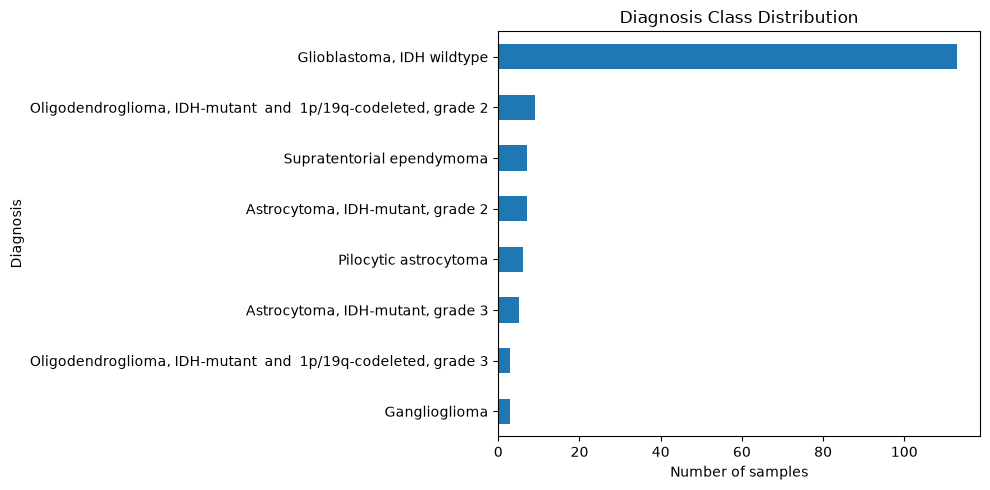

In [27]:

import matplotlib.pyplot as plt

# Visualize the class imbalance
class_counts = y.value_counts()

plt.figure(figsize=(10, 5))
class_counts.sort_values().plot(kind="barh")
plt.xlabel("Number of samples")
plt.ylabel("Diagnosis")
plt.title("Diagnosis Class Distribution")
plt.tight_layout()
plt.show()


In [28]:

# Inspect every diagnosis class and its sample count

class_summary = (
    y.value_counts()
    .rename_axis("Diagnosis")
    .reset_index(name="Sample_Count")
)

class_summary["Percentage"] = (
    class_summary["Sample_Count"] / len(y) * 100
).round(2)

display(class_summary)

print("\nTotal samples:", len(y))
print("Total classes:", y.nunique())
print(
    "Samples in classes with fewer than 10 examples:",
    class_summary.loc[
        class_summary["Sample_Count"] < 10,
        "Sample_Count"
    ].sum()
)


,Diagnosis,Sample_Count,Percentage
0,"Glioblastoma, IDH wildtype",113,73.86
1,"Oligodendroglioma, IDH-mutant and 1p/19q-cod...",9,5.88
2,"Astrocytoma, IDH-mutant, grade 2",7,4.58
3,Supratentorial ependymoma,7,4.58
4,Pilocytic astrocytoma,6,3.92
5,"Astrocytoma, IDH-mutant, grade 3",5,3.27
6,Ganglioglioma,3,1.96
7,"Oligodendroglioma, IDH-mutant and 1p/19q-cod...",3,1.96



Total samples: 153
Total classes: 8
Samples in classes with fewer than 10 examples: 40


In [29]:

# Inspect a proposed binary target; do not train yet

positive_label = "Glioblastoma, IDH wildtype"

y_binary = (y == positive_label).astype(int)

print("Class 0: Other diagnoses")
print("Class 1: Glioblastoma, IDH wildtype")
print()

print(y_binary.value_counts().sort_index().rename({
    0: "Other diagnoses",
    1: "Glioblastoma, IDH wildtype"
}))

print("\nClass percentages:")
print((y_binary.value_counts(normalize=True).sort_index() * 100).round(2))


Class 0: Other diagnoses
Class 1: Glioblastoma, IDH wildtype

Sample_ID
Other diagnoses    153
Name: count, dtype: int64

Class percentages:
Sample_ID
0    100.0
Name: proportion, dtype: float64


In [30]:

# Debug the exact diagnosis labels

positive_label = "Glioblastoma, IDH wildtype"

print("Target label:", repr(positive_label))
print("\nDiagnosis labels found in y:")

for label in y.unique():
    print(repr(label))

print("\nExact matches:", (y == positive_label).sum())

print("\nLabels containing 'Glioblastoma':")
for label in y.unique():
    if "Glioblastoma" in str(label):
        print(repr(label), "| Count:", (y == label).sum())


Target label: 'Glioblastoma, IDH wildtype'

Diagnosis labels found in y:
'Glioblastoma,\xa0IDH\xa0wildtype'
'Astrocytoma,\xa0IDH-mutant,\xa0grade\xa02'
'Pilocytic\xa0astrocytoma'
'Astrocytoma,\xa0IDH-mutant,\xa0grade\xa03'
'Ganglioglioma'
'Oligodendroglioma,\xa0IDH-mutant\xa0\xa0and\xa0\xa01p/19q-codeleted,\xa0grade\xa03'
'Oligodendroglioma,\xa0IDH-mutant\xa0\xa0and\xa0\xa01p/19q-codeleted,\xa0grade\xa02'
'Supratentorial\xa0ependymoma'

Exact matches: 0

Labels containing 'Glioblastoma':
'Glioblastoma,\xa0IDH\xa0wildtype' | Count: 113


In [31]:

# Normalize whitespace in diagnosis labels

y_clean = (
    y.astype(str)
    .str.replace("\u00a0", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

positive_label = "Glioblastoma, IDH wildtype"

y_binary = (y_clean == positive_label).astype("int64")

print("Cleaned diagnosis counts:")
print(y_clean.value_counts())

print("\nBinary class counts:")
print(y_binary.value_counts().sort_index())

print("\nGlioblastoma matches:", int(y_binary.sum()))
print("Total samples:", len(y_binary))

assert len(y_binary) == len(X)
assert y_binary.sum() == 113
assert y_binary.nunique() == 2

print("\nLabel cleaning and binary-target checks passed!")


Cleaned diagnosis counts:
Sample_ID
Glioblastoma, IDH wildtype                                     113
Oligodendroglioma, IDH-mutant and 1p/19q-codeleted, grade 2      9
Astrocytoma, IDH-mutant, grade 2                                 7
Supratentorial ependymoma                                        7
Pilocytic astrocytoma                                            6
Astrocytoma, IDH-mutant, grade 3                                 5
Ganglioglioma                                                    3
Oligodendroglioma, IDH-mutant and 1p/19q-codeleted, grade 3      3
Name: count, dtype: int64

Binary class counts:
Sample_ID
0     40
1    113
Name: count, dtype: int64

Glioblastoma matches: 113
Total samples: 153

Label cleaning and binary-target checks passed!


In [32]:

from sklearn.model_selection import train_test_split

# Split sample indices so X and y stay aligned
indices = np.arange(len(X))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y_binary
)

print("Training samples:", len(train_idx))
print("Testing samples:", len(test_idx))

print("\nTraining class distribution:")
print(y_binary.iloc[train_idx].value_counts().sort_index())

print("\nTesting class distribution:")
print(y_binary.iloc[test_idx].value_counts().sort_index())

assert len(set(train_idx) & set(test_idx)) == 0
assert len(train_idx) + len(test_idx) == len(X)

print("\nTrain/test split checks passed!")


Training samples: 122
Testing samples: 31

Training class distribution:
Sample_ID
0    32
1    90
Name: count, dtype: int64

Testing class distribution:
Sample_ID
0     8
1    23
Name: count, dtype: int64

Train/test split checks passed!


In [33]:

# Inspect gene variability using training samples only

X_train_raw = X.iloc[train_idx]

gene_variance = X_train_raw.var(axis=0)

print("Training samples:", X_train_raw.shape[0])
print("Total genes:", X_train_raw.shape[1])

print("\nGene variance summary:")
display(gene_variance.describe().to_frame("Variance"))

print("\nGenes with zero variance:", int((gene_variance == 0).sum()))
print("Genes with non-zero variance:", int((gene_variance > 0).sum()))

print("\nTop 10 most variable genes:")
display(
    gene_variance.sort_values(ascending=False)
    .head(10)
    .to_frame("Variance")
)


Training samples: 122
Total genes: 40232

Gene variance summary:


,Variance
count,4.023200e+04
mean,1.763889e+04
std,9.353846e+05
min,0.000000e+00
25%,8.196721e-03
50%,8.103577e-01
75%,7.143048e+01
max,1.324065e+08



Genes with zero variance: 8696
Genes with non-zero variance: 31536

Top 10 most variable genes:


,Variance
30849,1.324065e+08
28610,6.670120e+07
30641,6.544151e+07
36851,5.936972e+07
32953,4.202929e+07
3264,2.492598e+07
24765,2.286054e+07
26336,2.225457e+07
23568,2.211256e+07
11427,1.853354e+07


In [34]:

# Keep genes with non-zero variance in training samples

variable_genes = gene_variance[gene_variance > 0].index

X_train_variable = X_train_raw.loc[:, variable_genes]

print("Original number of genes:", X_train_raw.shape[1])
print("Genes with non-zero variance:", len(variable_genes))
print("Training matrix after filtering:", X_train_variable.shape)

assert X_train_variable.shape[1] == len(variable_genes)
assert (X_train_variable.var(axis=0) > 0).all()

print("\nZero-variance filtering passed!")


Original number of genes: 40232
Genes with non-zero variance: 31536
Training matrix after filtering: (122, 31536)

Zero-variance filtering passed!


In [35]:

# Apply log1p to the training data only (temporary transformed copy)

X_train_log = np.log1p(X_train_variable)

print("Training matrix shape:", X_train_log.shape)

print("\nTransformed value summary:")
display(X_train_log.describe().T[["mean", "std", "min", "max"]].describe())

print("\nTransformed values finite:",
      np.isfinite(X_train_log.to_numpy()).all())

print("Transformed values non-negative:",
      (X_train_log.to_numpy() >= 0).all())


Training matrix shape: (122, 31536)

Transformed value summary:


,mean,std,min,max
count,31536.000000,31536.000000,31536.000000,31536.000000
mean,1.554700,0.439574,0.676485,2.993384
std,1.590972,0.292851,1.122922,1.799817
min,0.005682,0.062755,0.000000,0.693147
25%,0.078149,0.251904,0.000000,1.386294
50%,0.969000,0.380652,0.000000,2.944439
75%,2.891138,0.567218,1.098612,4.394449
max,10.471656,3.183625,9.703999,11.409918



Transformed values finite: True
Transformed values non-negative: True


In [36]:

# Select the 500 most variable genes using training samples only

TOP_K = 500

gene_variance_log = X_train_log.var(axis=0)

selected_genes = (
    gene_variance_log
    .sort_values(ascending=False)
    .head(TOP_K)
    .index
)

X_train_selected = X_train_log.loc[:, selected_genes]

print("Genes before selection:", X_train_log.shape[1])
print("Selected genes:", len(selected_genes))
print("Training matrix after selection:", X_train_selected.shape)

print("\nTop 10 selected genes:")
display(gene_variance_log.loc[selected_genes].head(10).to_frame("Log-expression variance"))

assert len(selected_genes) == TOP_K
assert X_train_selected.shape == (len(train_idx), TOP_K)

print("\nTraining-only gene selection passed!")


Genes before selection: 31536
Selected genes: 500
Training matrix after selection: (122, 500)

Top 10 selected genes:


,Log-expression variance
40159,10.135470
5380,9.659324
29063,9.601316
5402,9.482100
36213,9.397644
27841,9.391292
36359,9.333742
36219,9.283245
4819,8.696361
32381,7.786878



Training-only gene selection passed!


In [37]:

# Prepare train and test matrices using the same selected genes

# Training data: selected using training-only variance
X_train_final = X_train_selected.copy()

# Test data: use the same genes selected from training data
X_test_raw = X.iloc[test_idx].loc[:, selected_genes]
X_test_final = np.log1p(X_test_raw)

# Align labels with their corresponding samples
y_train = y_binary.iloc[train_idx].to_numpy(dtype=np.int64)
y_test = y_binary.iloc[test_idx].to_numpy(dtype=np.int64)

print("Training features:", X_train_final.shape)
print("Testing features:", X_test_final.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nTrain/test gene order identical:",
      X_train_final.columns.equals(X_test_final.columns))

print("Test values finite:",
      np.isfinite(X_test_final.to_numpy()).all())

assert X_train_final.shape == (len(train_idx), 500)
assert X_test_final.shape == (len(test_idx), 500)
assert X_train_final.columns.equals(X_test_final.columns)
assert np.isfinite(X_test_final.to_numpy()).all()

print("\nTrain/test feature preparation passed!")


Training features: (122, 500)
Testing features: (31, 500)
Training labels: (122,)
Testing labels: (31,)

Train/test gene order identical: True
Test values finite: True

Train/test feature preparation passed!


In [38]:

import torch
import torch.nn as nn

# Gene-wise token embedding
class GeneTokenEmbedding(nn.Module):
    def __init__(self, embed_dim=32):
        super().__init__()
        self.projection = nn.Linear(1, embed_dim)

    def forward(self, x):
        # x shape: (batch_size, num_genes)
        x = x.unsqueeze(-1)
        # shape: (batch_size, num_genes, 1)
        return self.projection(x)
    
# Test using a small batch from training data
torch.manual_seed(42)

embedding = GeneTokenEmbedding(embed_dim=32)
sample_batch = torch.tensor(
    X_train_final.iloc[:4].to_numpy(),
    dtype=torch.float32
)

embedded = embedding(sample_batch)

print("Input shape:", sample_batch.shape)
print("Embedded shape:", embedded.shape)

assert sample_batch.shape == (4, 500)
assert embedded.shape == (4, 500, 32)

print("Gene-token embedding test passed!")


Input shape: torch.Size([4, 500])
Embedded shape: torch.Size([4, 500, 32])
Gene-token embedding test passed!


In [39]:

# Test self-attention on gene-token embeddings

# Reuse your existing SelfAttention class
attention = SelfAttention(embed_dim=32)

# embedded comes from the previous GeneTokenEmbedding cell
attention_output, attention_weights = attention(embedded)

print("Input embeddings:", embedded.shape)
print("Attention output:", attention_output.shape)
print("Attention weights:", attention_weights.shape)

assert attention_output.shape == (4, 500, 32)
assert attention_weights.shape == (4, 500, 500)

# Each gene's attention weights should sum to approximately 1
attention_sums = attention_weights.sum(dim=-1)

print(
    "Attention weights sum to 1:",
    torch.allclose(
        attention_sums,
        torch.ones_like(attention_sums),
        atol=1e-5
    )
)

print("Gene self-attention test passed!")


Input embeddings: torch.Size([4, 500, 32])
Attention output: torch.Size([4, 500, 32])
Attention weights: torch.Size([4, 500, 500])
Attention weights sum to 1: True
Gene self-attention test passed!


In [40]:

# Complete gene-expression Self-Attention classifier

class GeneExpressionAttentionClassifier(nn.Module):
    def __init__(
        self,
        num_genes=500,
        embed_dim=32,
        hidden_dim=32,
        num_classes=2,
        dropout=0.3
    ):
        super().__init__()

        self.embedding = GeneTokenEmbedding(embed_dim=embed_dim)
        self.attention = SelfAttention(embed_dim=embed_dim)

        self.classifier = nn.Sequential(
            nn.Linear(embed_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x):
        # x: (batch_size, num_genes)
        tokens = self.embedding(x)

        # Attention between gene tokens
        attended, attention_weights = self.attention(tokens)

        # Aggregate gene representations
        pooled = attended.mean(dim=1)

        # Predict class logits
        logits = self.classifier(pooled)

        return logits, attention_weights


# Test the complete architecture
torch.manual_seed(42)

model = GeneExpressionAttentionClassifier()
test_batch = torch.tensor(
    X_train_final.iloc[:4].to_numpy(),
    dtype=torch.float32
)

logits, attention_weights = model(test_batch)

print("Input shape:", test_batch.shape)
print("Logits shape:", logits.shape)
print("Attention weights shape:", attention_weights.shape)

print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

assert logits.shape == (4, 2)
assert attention_weights.shape == (4, 500, 500)

print("Complete classifier architecture test passed!")


Input shape: torch.Size([4, 500])
Logits shape: torch.Size([4, 2])
Attention weights shape: torch.Size([4, 500, 500])
Trainable parameters: 4354
Complete classifier architecture test passed!


In [41]:

# Prepare PyTorch tensors for training and testing

X_train_tensor = torch.tensor(
    X_train_final.to_numpy(),
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_final.to_numpy(),
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.long
)

print("X_train:", X_train_tensor.shape, X_train_tensor.dtype)
print("y_train:", y_train_tensor.shape, y_train_tensor.dtype)
print("X_test:", X_test_tensor.shape, X_test_tensor.dtype)
print("y_test:", y_test_tensor.shape, y_test_tensor.dtype)

print("\nTraining class counts:", torch.bincount(y_train_tensor))
print("Testing class counts:", torch.bincount(y_test_tensor))

assert X_train_tensor.shape == (122, 500)
assert X_test_tensor.shape == (31, 500)
assert y_train_tensor.dtype == torch.long
assert y_test_tensor.dtype == torch.long

print("\nPyTorch tensor preparation passed!")


X_train: torch.Size([122, 500]) torch.float32
y_train: torch.Size([122]) torch.int64
X_test: torch.Size([31, 500]) torch.float32
y_test: torch.Size([31]) torch.int64

Training class counts: tensor([32, 90])
Testing class counts: tensor([ 8, 23])

PyTorch tensor preparation passed!


In [42]:

from sklearn.model_selection import train_test_split
import numpy as np

# Split sample indices: 80% development, 20% final test
all_indices = np.arange(len(X))

dev_idx, test_idx = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=42,
    stratify=y_binary
)

# Split development data into training and validation
train_idx, val_idx = train_test_split(
    dev_idx,
    test_size=0.20,
    random_state=42,
    stratify=y_binary.iloc[dev_idx]
)

print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Final test samples:", len(test_idx))

print("\nTraining class counts:")
print(y_binary.iloc[train_idx].value_counts().sort_index())

print("\nValidation class counts:")
print(y_binary.iloc[val_idx].value_counts().sort_index())

print("\nTest class counts:")
print(y_binary.iloc[test_idx].value_counts().sort_index())

assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0
assert len(train_idx) + len(val_idx) + len(test_idx) == len(X)

print("\nThree-way split checks passed!")


Training samples: 97
Validation samples: 25
Final test samples: 31

Training class counts:
Sample_ID
0    25
1    72
Name: count, dtype: int64

Validation class counts:
Sample_ID
0     7
1    18
Name: count, dtype: int64

Test class counts:
Sample_ID
0     8
1    23
Name: count, dtype: int64

Three-way split checks passed!


In [43]:

# Leakage-safe gene selection using training samples only

X_train_raw = X.iloc[train_idx]
X_val_raw = X.iloc[val_idx]
X_test_raw = X.iloc[test_idx]

# Remove genes with zero variance in training samples
train_variance = X_train_raw.var(axis=0)
variable_genes = train_variance[train_variance > 0].index

X_train_variable = X_train_raw.loc[:, variable_genes]

# Apply log1p transformation
X_train_log = np.log1p(X_train_variable)

# Select top 500 genes using training data only
TOP_K = 500

log_variance = X_train_log.var(axis=0)

selected_genes = (
    log_variance
    .sort_values(ascending=False)
    .head(TOP_K)
    .index
)

print("Training samples:", len(train_idx))
print("Genes after zero-variance filtering:", len(variable_genes))
print("Selected genes:", len(selected_genes))
print("Training matrix:", X_train_log[selected_genes].shape)

assert len(selected_genes) == TOP_K
assert X_train_log[selected_genes].shape == (97, 500)

print("\nTraining-only feature selection passed!")


Training samples: 97
Genes after zero-variance filtering: 31197
Selected genes: 500
Training matrix: (97, 500)

Training-only feature selection passed!


In [44]:

# Apply training-selected genes to validation and test sets

X_val_selected = np.log1p(
    X_val_raw.loc[:, selected_genes]
)

X_test_selected = np.log1p(
    X_test_raw.loc[:, selected_genes]
)

# Prepare labels
y_train = y_binary.iloc[train_idx].to_numpy(dtype=np.int64)
y_val = y_binary.iloc[val_idx].to_numpy(dtype=np.int64)
y_test = y_binary.iloc[test_idx].to_numpy(dtype=np.int64)

print("Training features:", X_train_log[selected_genes].shape)
print("Validation features:", X_val_selected.shape)
print("Test features:", X_test_selected.shape)

print("\nTraining labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Test labels:", y_test.shape)

print("\nAll feature values finite:",
      np.isfinite(X_train_log[selected_genes].to_numpy()).all()
      and np.isfinite(X_val_selected.to_numpy()).all()
      and np.isfinite(X_test_selected.to_numpy()).all())

assert X_train_log[selected_genes].shape == (97, 500)
assert X_val_selected.shape == (25, 500)
assert X_test_selected.shape == (31, 500)
assert np.isfinite(X_val_selected.to_numpy()).all()
assert np.isfinite(X_test_selected.to_numpy()).all()

print("\nTrain/validation/test feature preparation passed!")


Training features: (97, 500)
Validation features: (25, 500)
Test features: (31, 500)

Training labels: (97,)
Validation labels: (25,)
Test labels: (31,)

All feature values finite: True

Train/validation/test feature preparation passed!


In [45]:

from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# Training-selected genes, already log1p transformed
X_train_selected = X_train_log.loc[:, selected_genes].copy()

# Fit scaler on training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_selected)

# Apply the same scaler to validation and test data
X_val_scaled = scaler.transform(X_val_selected)
X_test_scaled = scaler.transform(X_test_selected)

print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Test shape:", X_test_scaled.shape)

print("\nTraining scaled mean (first 5 genes):")
print(np.round(X_train_scaled.mean(axis=0)[:5], 4))

print("\nTraining scaled std (first 5 genes):")
print(np.round(X_train_scaled.std(axis=0)[:5], 4))

print("\nAll scaled values finite:",
      np.isfinite(X_train_scaled).all()
      and np.isfinite(X_val_scaled).all()
      and np.isfinite(X_test_scaled).all())

assert X_train_scaled.shape == (97, 500)
assert X_val_scaled.shape == (25, 500)
assert X_test_scaled.shape == (31, 500)
assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_val_scaled).all()
assert np.isfinite(X_test_scaled).all()

print("\nScaling checks passed!")


Training shape: (97, 500)
Validation shape: (25, 500)
Test shape: (31, 500)

Training scaled mean (first 5 genes):
[-0.  0.  0.  0. -0.]

Training scaled std (first 5 genes):
[1. 1. 1. 1. 1.]

All scaled values finite: True

Scaling checks passed!


In [46]:

# Convert scaled features and labels into PyTorch tensors

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print("Training:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation:", X_val_tensor.shape, y_val_tensor.shape)
print("Testing:", X_test_tensor.shape, y_test_tensor.shape)

print("\nTraining class counts:", torch.bincount(y_train_tensor))
print("Validation class counts:", torch.bincount(y_val_tensor))
print("Testing class counts:", torch.bincount(y_test_tensor))

assert X_train_tensor.shape == (97, 500)
assert X_val_tensor.shape == (25, 500)
assert X_test_tensor.shape == (31, 500)

assert y_train_tensor.dtype == torch.long
assert y_val_tensor.dtype == torch.long
assert y_test_tensor.dtype == torch.long

print("\nPyTorch tensor preparation passed!")


Training: torch.Size([97, 500]) torch.Size([97])
Validation: torch.Size([25, 500]) torch.Size([25])
Testing: torch.Size([31, 500]) torch.Size([31])

Training class counts: tensor([25, 72])
Validation class counts: tensor([ 7, 18])
Testing class counts: tensor([ 8, 23])

PyTorch tensor preparation passed!


In [47]:

# Calculate class weights from training labels only

class_counts = torch.bincount(y_train_tensor)

num_classes = len(class_counts)
total_samples = len(y_train_tensor)

class_weights = total_samples / (
    num_classes * class_counts.float()
)

print("Training class counts:", class_counts)
print("Class weights:", class_weights)

print("\nClass 0 weight (other diagnoses):",
      round(class_weights[0].item(), 4))
print("Class 1 weight (Glioblastoma):",
      round(class_weights[1].item(), 4))

assert len(class_weights) == 2
assert torch.isfinite(class_weights).all()
assert (class_weights > 0).all()

print("\nClass-weight calculation passed!")


Training class counts: tensor([25, 72])
Class weights: tensor([1.9400, 0.6736])

Class 0 weight (other diagnoses): 1.94
Class 1 weight (Glioblastoma): 0.6736

Class-weight calculation passed!


In [48]:

# Configure the model for training

import torch
import torch.nn as nn

# Reinitialize the model with fresh parameters
torch.manual_seed(42)

model = GeneExpressionAttentionClassifier(
    num_genes=500,
    embed_dim=32,
    hidden_dim=32,
    num_classes=2,
    dropout=0.3
)

# Weighted loss to account for class imbalance
criterion = nn.CrossEntropyLoss(weight=class_weights)

# AdamW optimizer with weight decay
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-3
)

print("Model initialized.")
print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

print("\nTraining setup ready!")


Model initialized.
Loss function: CrossEntropyLoss()
Optimizer: AdamW
Learning rate: 0.001
Trainable parameters: 4354

Training setup ready!


In [49]:

# Train the model and monitor validation loss

import copy

EPOCHS = 50
PATIENCE = 8

best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

for epoch in range(EPOCHS):
    # Training phase
    model.train()
    optimizer.zero_grad()

    train_logits, _ = model(X_train_tensor)
    train_loss = criterion(train_logits, y_train_tensor)

    train_loss.backward()
    optimizer.step()

    train_predictions = train_logits.argmax(dim=1)
    train_accuracy = (
        train_predictions == y_train_tensor
    ).float().mean().item()

    # Validation phase
    model.eval()
    with torch.no_grad():
        val_logits, _ = model(X_val_tensor)
        val_loss = criterion(val_logits, y_val_tensor)

        val_predictions = val_logits.argmax(dim=1)
        val_accuracy = (
            val_predictions == y_val_tensor
        ).float().mean().item()

    train_loss_value = train_loss.item()
    val_loss_value = val_loss.item()

    history["train_loss"].append(train_loss_value)
    history["val_loss"].append(val_loss_value)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    # Save the best model using validation loss
    if val_loss_value < best_val_loss:
        best_val_loss = val_loss_value
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(
            f"Epoch {epoch + 1:02d} | "
            f"Train Loss: {train_loss_value:.4f} | "
            f"Val Loss: {val_loss_value:.4f} | "
            f"Train Acc: {train_accuracy:.3f} | "
            f"Val Acc: {val_accuracy:.3f}"
        )

    # Early stopping
    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch + 1}")
        break

# Restore the best validation-loss checkpoint
if best_state is not None:
    model.load_state_dict(best_state)

print("\nTraining complete.")
print("Best validation loss:", round(best_val_loss, 4))
print("Epochs completed:", len(history["train_loss"]))


Epoch 01 | Train Loss: 0.6923 | Val Loss: 0.7003 | Train Acc: 0.742 | Val Acc: 0.720
Epoch 05 | Train Loss: 0.6943 | Val Loss: 0.6940 | Train Acc: 0.598 | Val Acc: 0.720
Epoch 10 | Train Loss: 0.6923 | Val Loss: 0.6923 | Train Acc: 0.526 | Val Acc: 0.360
Epoch 15 | Train Loss: 0.6956 | Val Loss: 0.6912 | Train Acc: 0.433 | Val Acc: 0.520
Epoch 20 | Train Loss: 0.6838 | Val Loss: 0.6895 | Train Acc: 0.536 | Val Acc: 0.520
Epoch 25 | Train Loss: 0.6871 | Val Loss: 0.6840 | Train Acc: 0.515 | Val Acc: 0.560
Epoch 30 | Train Loss: 0.6679 | Val Loss: 0.6731 | Train Acc: 0.474 | Val Acc: 0.520
Epoch 35 | Train Loss: 0.6781 | Val Loss: 0.6629 | Train Acc: 0.464 | Val Acc: 0.600
Epoch 40 | Train Loss: 0.6740 | Val Loss: 0.6505 | Train Acc: 0.546 | Val Acc: 0.680
Epoch 45 | Train Loss: 0.6605 | Val Loss: 0.6471 | Train Acc: 0.619 | Val Acc: 0.680
Epoch 50 | Train Loss: 0.6467 | Val Loss: 0.6264 | Train Acc: 0.639 | Val Acc: 0.680

Training complete.
Best validation loss: 0.6264
Epochs completed

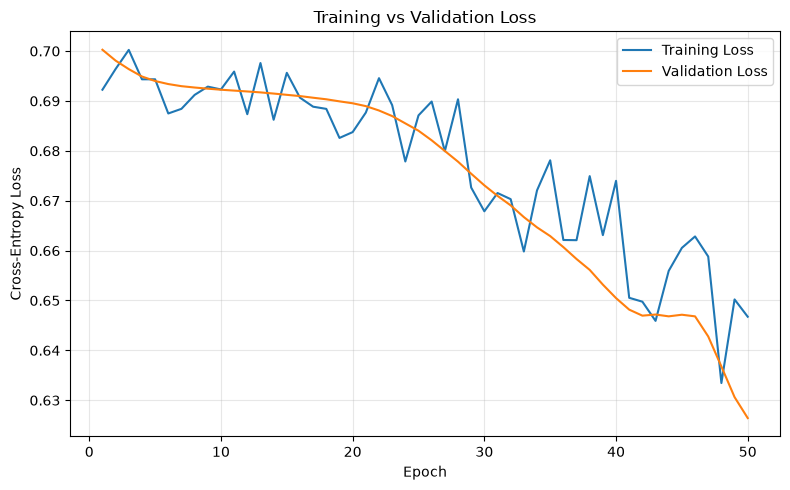

In [50]:

import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], label="Training Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [51]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    balanced_accuracy_score
)

# Evaluate the best checkpoint on validation data
model.eval()

with torch.no_grad():
    val_logits, _ = model(X_val_tensor)
    val_predictions = val_logits.argmax(dim=1).cpu().numpy()

y_val_true = y_val_tensor.cpu().numpy()

print("Validation confusion matrix:")
print(confusion_matrix(y_val_true, val_predictions, labels=[0, 1]))

print("\nClass-wise report:")
print(
    classification_report(
        y_val_true,
        val_predictions,
        labels=[0, 1],
        target_names=["Other diagnoses", "Glioblastoma"],
        zero_division=0
    )
)

print(
    "Balanced accuracy:",
    round(balanced_accuracy_score(y_val_true, val_predictions), 4)
)


Validation confusion matrix:
[[ 5  2]
 [ 6 12]]

Class-wise report:
                 precision    recall  f1-score   support

Other diagnoses       0.45      0.71      0.56         7
   Glioblastoma       0.86      0.67      0.75        18

       accuracy                           0.68        25
      macro avg       0.66      0.69      0.65        25
   weighted avg       0.74      0.68      0.70        25

Balanced accuracy: 0.6905


In [52]:

# Inspect validation prediction probabilities

import torch.nn.functional as F
import pandas as pd

model.eval()

with torch.no_grad():
    val_logits, _ = model(X_val_tensor)
    val_probs = F.softmax(val_logits, dim=1)

confidence_df = pd.DataFrame({
    "Actual": y_val_tensor.numpy(),
    "Predicted": val_probs.argmax(dim=1).numpy(),
    "P_Other": val_probs[:, 0].numpy(),
    "P_Glioblastoma": val_probs[:, 1].numpy()
})

confidence_df["Confidence"] = val_probs.max(dim=1).values.numpy()

print("First 10 validation predictions:")
display(confidence_df.head(10).round(3))

print("\nPrediction confidence summary:")
display(confidence_df["Confidence"].describe().round(3))


First 10 validation predictions:


,Actual,Predicted,P_Other,P_Glioblastoma,Confidence
0,1,0,0.627,0.373,0.627
1,1,1,0.473,0.527,0.527
2,1,1,0.367,0.633,0.633
3,1,1,0.408,0.592,0.592
4,0,1,0.376,0.624,0.624
5,1,1,0.378,0.622,0.622
6,1,1,0.345,0.655,0.655
7,1,1,0.444,0.556,0.556
8,0,0,0.685,0.315,0.685
9,1,1,0.390,0.610,0.610



Prediction confidence summary:


count    25.000
mean      0.588
std       0.050
min       0.505
25%       0.556
50%       0.578
75%       0.624
max       0.685
Name: Confidence, dtype: float64

In [53]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)
import numpy as np

# Baseline: predict the majority class for every validation sample
majority_class = int(
    np.bincount(y_train).argmax()
)

baseline_predictions = np.full(
    len(y_val),
    majority_class
)

print("Majority class predicted:", majority_class)
print("Baseline accuracy:",
      round(accuracy_score(y_val, baseline_predictions), 4))
print("Baseline balanced accuracy:",
      round(balanced_accuracy_score(y_val, baseline_predictions), 4))
print("Baseline macro F1:",
      round(f1_score(
          y_val,
          baseline_predictions,
          average="macro",
          zero_division=0
      ), 4))

print("\nSelf-Attention model accuracy:",
      round(accuracy_score(y_val, val_predictions), 4))
print("Self-Attention balanced accuracy:",
      round(balanced_accuracy_score(y_val, val_predictions), 4))
print("Self-Attention macro F1:",
      round(f1_score(
          y_val,
          val_predictions,
          average="macro",
          zero_division=0
      ), 4))


Majority class predicted: 1
Baseline accuracy: 0.72
Baseline balanced accuracy: 0.5
Baseline macro F1: 0.4186

Self-Attention model accuracy: 0.68
Self-Attention balanced accuracy: 0.6905
Self-Attention macro F1: 0.6528


In [54]:

import numpy as np

best_epoch = int(np.argmin(history["val_loss"])) + 1

print("Best epoch:", best_epoch)
print("Best validation loss:", round(min(history["val_loss"]), 4))
print("Training loss at best epoch:",
      round(history["train_loss"][best_epoch - 1], 4))
print("Validation accuracy at best epoch:",
      round(history["val_accuracy"][best_epoch - 1], 4))
print("Training accuracy at best epoch:",
      round(history["train_accuracy"][best_epoch - 1], 4))


Best epoch: 50
Best validation loss: 0.6264
Training loss at best epoch: 0.6467
Validation accuracy at best epoch: 0.68
Training accuracy at best epoch: 0.6392


In [55]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Fit baseline using training data only
baseline_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

baseline_model.fit(X_train_scaled, y_train)

# Validation predictions only; final test remains untouched
lr_val_predictions = baseline_model.predict(X_val_scaled)

print("LOGISTIC REGRESSION — VALIDATION")
print("Accuracy:",
      round(accuracy_score(y_val, lr_val_predictions), 4))
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_val, lr_val_predictions), 4))
print("Macro F1:",
      round(f1_score(
          y_val,
          lr_val_predictions,
          average="macro",
          zero_division=0
      ), 4))

print("\nClass-wise report:")
print(classification_report(
    y_val,
    lr_val_predictions,
    labels=[0, 1],
    target_names=["Other diagnoses", "Glioblastoma"],
    zero_division=0
))


LOGISTIC REGRESSION — VALIDATION
Accuracy: 0.92
Balanced accuracy: 0.9444
Macro F1: 0.9081

Class-wise report:
                 precision    recall  f1-score   support

Other diagnoses       0.78      1.00      0.88         7
   Glioblastoma       1.00      0.89      0.94        18

       accuracy                           0.92        25
      macro avg       0.89      0.94      0.91        25
   weighted avg       0.94      0.92      0.92        25



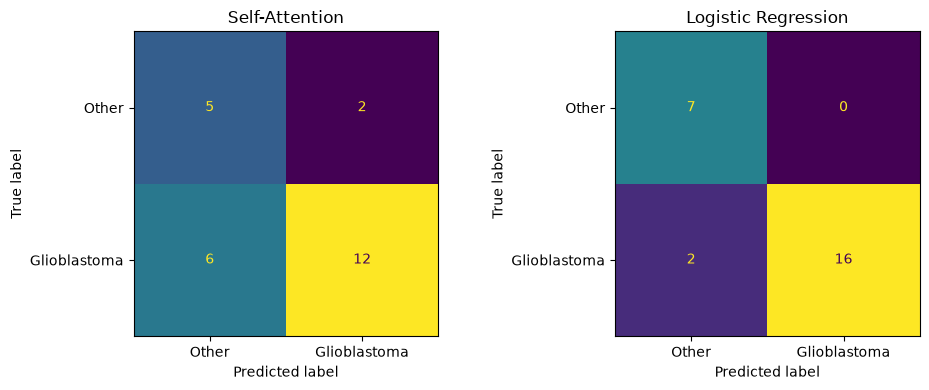

In [56]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Compare validation predictions only
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_predictions,
    labels=[0, 1],
    display_labels=["Other", "Glioblastoma"],
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Self-Attention")

ConfusionMatrixDisplay.from_predictions(
    y_val,
    lr_val_predictions,
    labels=[0, 1],
    display_labels=["Other", "Glioblastoma"],
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Logistic Regression")

plt.tight_layout()
plt.show()


In [57]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Custom Self-Attention",
        "Accuracy": accuracy_score(y_val, val_predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_val, val_predictions),
        "Macro F1": f1_score(
            y_val, val_predictions,
            average="macro", zero_division=0
        )
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_val, lr_val_predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_val, lr_val_predictions),
        "Macro F1": f1_score(
            y_val, lr_val_predictions,
            average="macro", zero_division=0
        )
    }
])

display(comparison.round(4))


,Model,Accuracy,Balanced Accuracy,Macro F1
0,Custom Self-Attention,0.68,0.6905,0.6528
1,Logistic Regression,0.92,0.9444,0.9081


In [58]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd
import torch

# Model 1: Custom Self-Attention
model.eval()

with torch.no_grad():
    test_logits, _ = model(X_test_tensor)
    attention_test_predictions = test_logits.argmax(dim=1).cpu().numpy()

# Model 2: Logistic Regression
logistic_test_predictions = baseline_model.predict(X_test_scaled)

# True test labels
y_test_true = y_test_tensor.cpu().numpy()

# Compare both models on the same untouched test set
results = []

for name, predictions in [
    ("Custom Self-Attention", attention_test_predictions),
    ("Logistic Regression", logistic_test_predictions)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_true, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test_true, predictions
        ),
        "Macro F1": f1_score(
            y_test_true, predictions,
            average="macro", zero_division=0
        )
    })

test_comparison = pd.DataFrame(results)

print("FINAL TEST COMPARISON")
display(test_comparison.round(4))

for name, predictions in [
    ("Custom Self-Attention", attention_test_predictions),
    ("Logistic Regression", logistic_test_predictions)
]:
    print(f"\n{name} — Classification Report")
    print(classification_report(
        y_test_true,
        predictions,
        labels=[0, 1],
        target_names=["Other diagnoses", "Glioblastoma"],
        zero_division=0
    ))

    print("Confusion matrix:")
    print(confusion_matrix(y_test_true, predictions, labels=[0, 1]))


FINAL TEST COMPARISON


,Model,Accuracy,Balanced Accuracy,Macro F1
0,Custom Self-Attention,0.6774,0.6603,0.6310
1,Logistic Regression,0.8710,0.7908,0.8155



Custom Self-Attention — Classification Report
                 precision    recall  f1-score   support

Other diagnoses       0.42      0.62      0.50         8
   Glioblastoma       0.84      0.70      0.76        23

       accuracy                           0.68        31
      macro avg       0.63      0.66      0.63        31
   weighted avg       0.73      0.68      0.69        31

Confusion matrix:
[[ 5  3]
 [ 7 16]]

Logistic Regression — Classification Report
                 precision    recall  f1-score   support

Other diagnoses       0.83      0.62      0.71         8
   Glioblastoma       0.88      0.96      0.92        23

       accuracy                           0.87        31
      macro avg       0.86      0.79      0.82        31
   weighted avg       0.87      0.87      0.86        31

Confusion matrix:
[[ 5  3]
 [ 1 22]]


In [59]:

import numpy as np
import torch
import torch.nn.functional as F

# Select one sample from the held-out test set
sample_position = 0

x_sample = X_test_tensor[
    sample_position:sample_position + 1
]
actual_label = int(y_test_tensor[sample_position].item())

label_names = {
    0: "Other diagnoses",
    1: "Glioblastoma, IDH wildtype"
}

# 1. Custom Self-Attention prediction
model.eval()

with torch.no_grad():
    logits, attention_weights = model(x_sample)
    probs = F.softmax(logits, dim=1)[0].cpu().numpy()
    pred_attention = int(np.argmax(probs))

# 2. Logistic Regression prediction
lr_probs = baseline_model.predict_proba(
    X_test_scaled[sample_position:sample_position + 1]
)[0]
pred_lr = int(np.argmax(lr_probs))

# Display results
print("=" * 45)
print("BRAIN TUMOR CLASSIFICATION DEMO")
print("=" * 45)

print("Sample position:", sample_position)
print("Actual class:", label_names[actual_label])

print("\n--- Custom Self-Attention ---")
print("Prediction:", label_names[pred_attention])
print(f"Other diagnoses probability: {probs[0]:.2%}")
print(f"Glioblastoma probability: {probs[1]:.2%}")
print("Correct prediction:", pred_attention == actual_label)

print("\n--- Logistic Regression ---")
print("Prediction:", label_names[pred_lr])
print(f"Other diagnoses probability: {lr_probs[0]:.2%}")
print(f"Glioblastoma probability: {lr_probs[1]:.2%}")
print("Correct prediction:", pred_lr == actual_label)

print("\nAttention matrix shape:", tuple(attention_weights.shape))
print("Demo completed.")


BRAIN TUMOR CLASSIFICATION DEMO
Sample position: 0
Actual class: Other diagnoses

--- Custom Self-Attention ---
Prediction: Glioblastoma, IDH wildtype
Other diagnoses probability: 39.20%
Glioblastoma probability: 60.80%
Correct prediction: False

--- Logistic Regression ---
Prediction: Other diagnoses
Other diagnoses probability: 98.12%
Glioblastoma probability: 1.88%
Correct prediction: True

Attention matrix shape: (1, 500, 500)
Demo completed.
